# Signals and Systems Final Project: Voice Changer

## Course
ECE 2700 Signals & Systems, Professor Rohde

## Authors
Caleb Wiese (kzt5su), Kyle Song (tsr3km)

## Objective
The goal of this project is to apply fundamental concepts from signals and systems to a recorded voice signal by analyzing and modifying it in both the time and frequency domains. In this notebook, the original audio signal is loaded, visualized as a waveform, and transformed into the frequency domain using the Fourier Transform to examine its spectral content.

A series of audio effects including echo, reverb, low-pass filtering, bandpass filtering, high-pass filtering, and pitch shifting (high and low pitch) are then implemented to modify the signal. Each effect is designed to demonstrate a key signal processing concept such as time shifting, convolution, frequency-domain filtering, and resampling. By comparing the signal before and after each transformation in both domains, this project highlights how these operations influence the structure and perception of audio signals.

Note: you may need to upload your own .wav file and name it "example.wav"

In [ ]:
# NumPy is used for numerical operations and signal manipulation
import numpy as np

# Matplotlib is used to visualize the signal
import matplotlib.pyplot as plt

# soundfile is used to read the audio file
import soundfile as sf

# Used to play audio inside the notebook
from IPython.display import Audio, display

In [ ]:
import os

# File name
audio_path = os.path.join("sample_data", "example.wav")

# Read the audio file
signal, sr = sf.read(audio_path)

# Convert stereo → mono if needed
if len(signal.shape) > 1:
    signal = np.mean(signal, axis=1)

# Compute duration
duration = len(signal) / sr

# Print info
print("Sample rate:", sr)
print("Duration:", duration, "seconds")

# Play audio
display(Audio(signal, rate=sr))

Sample rate: 44100
Duration: 7.732244897959184 seconds


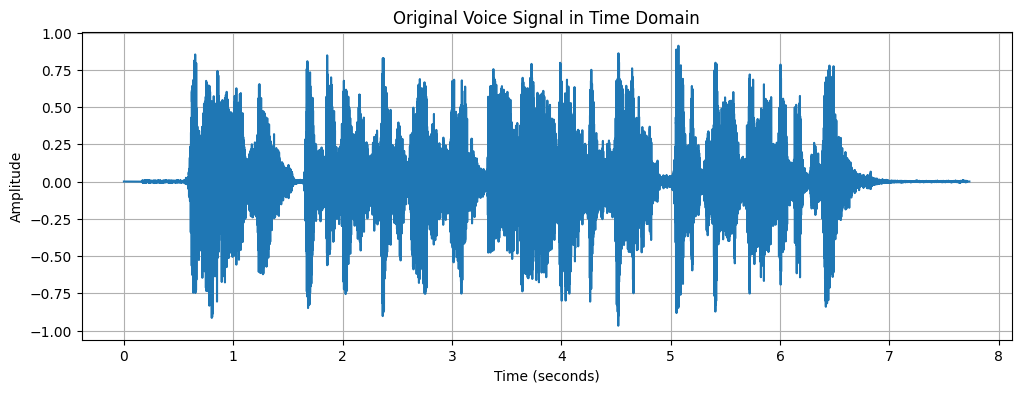

In [ ]:
# Create time axis
time = np.linspace(0, duration, len(signal))

# Plot waveform
plt.figure(figsize=(12, 4))
plt.plot(time, signal)
plt.title("Original Voice Signal in Time Domain")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

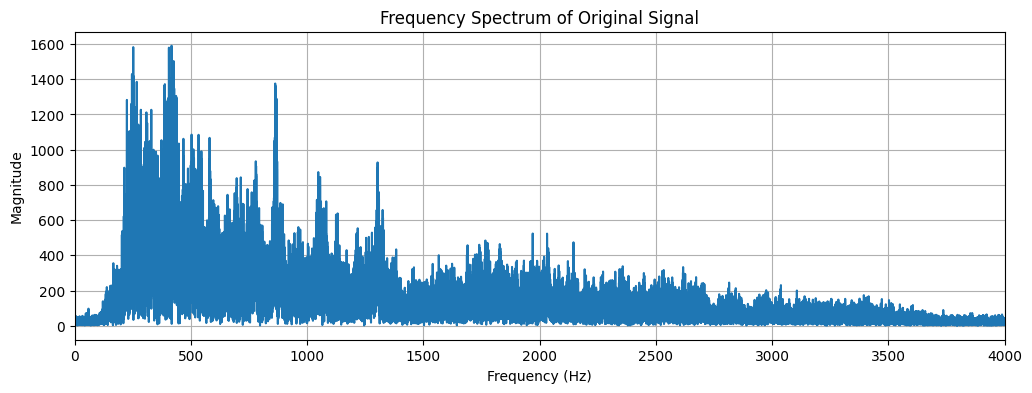

In [ ]:
# Compute FFT
fft_vals = np.fft.fft(signal)

# Magnitude of frequencies
fft_magnitude = np.abs(fft_vals)

# Frequency axis
freqs = np.fft.fftfreq(len(signal), 1 / sr)

# Keep only positive frequencies
positive_freqs = freqs[:len(freqs)//2]
positive_fft = fft_magnitude[:len(fft_magnitude)//2]

# Plot frequency spectrum
plt.figure(figsize=(12, 4))
plt.plot(positive_freqs, positive_fft)
plt.title("Frequency Spectrum of Original Signal")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, 4000)  # focus on voice range
plt.grid(True)
plt.show()

### Low-Pass Filter Effect

A low-pass filter allows frequencies below a certain cutoff frequency to pass through and attenuates or removes frequencies above it. In the frequency domain, this is achieved by setting the FFT components corresponding to frequencies above the cutoff to zero.

Mathematically, if $X(k)$ is the Discrete Fourier Transform (DFT) of a signal $x[n]$, and $f_c$ is the cutoff frequency, the filtered FFT $Y(k)$ is given by:

$$Y(k) = \begin{cases} X(k) & \text{if } |f_k| \le f_c \\ 0 & \text{if } |f_k| > f_c \end{cases}$$

Where $f_k$ are the frequencies corresponding to the DFT bins. After applying this filter in the frequency domain, an Inverse Fast Fourier Transform (IFFT) is performed to convert the signal back to the time domain, resulting in $y[n]$.

In [ ]:
# Low-Pass Filter Effect
# Removes high-frequency components

cutoff_freq = 1200  # Hz

print(f"Low-Pass Filter Cutoff Frequency: {cutoff_freq} Hz")
print(f"Original signal length: {len(signal)} samples")

# FFT of signal
fft_vals = np.fft.fft(signal)

# Frequency axis
freqs = np.fft.fftfreq(len(signal), 1/sr)

# Copy FFT
filtered_fft = np.copy(fft_vals)

# Apply filter
for i in range(len(freqs)):
    if abs(freqs[i]) > cutoff_freq:
        filtered_fft[i] = 0

# Inverse FFT
lowpass_signal = np.real(np.fft.ifft(filtered_fft))

# Normalize
lowpass_signal = lowpass_signal / np.max(np.abs(lowpass_signal))

print(f"Low-pass filtered signal length: {len(lowpass_signal)} samples")

# Play result
display(Audio(lowpass_signal, rate=sr))

Low-Pass Filter Cutoff Frequency: 1200 Hz
Original signal length: 340992 samples
Low-pass filtered signal length: 340992 samples


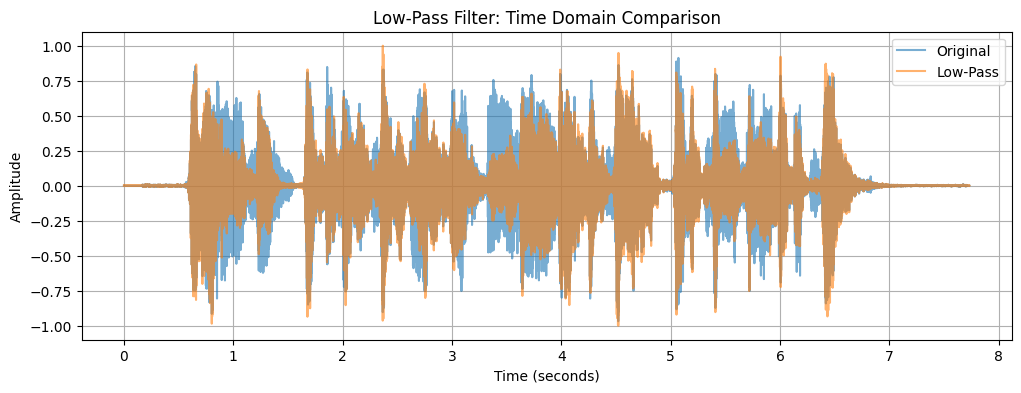

In [ ]:
# Time Comparison
plt.figure(figsize=(12, 4))
plt.plot(time, signal, label="Original", alpha=0.6)
plt.plot(time, lowpass_signal, label="Low-Pass", alpha=0.6)

plt.title("Low-Pass Filter: Time Domain Comparison")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

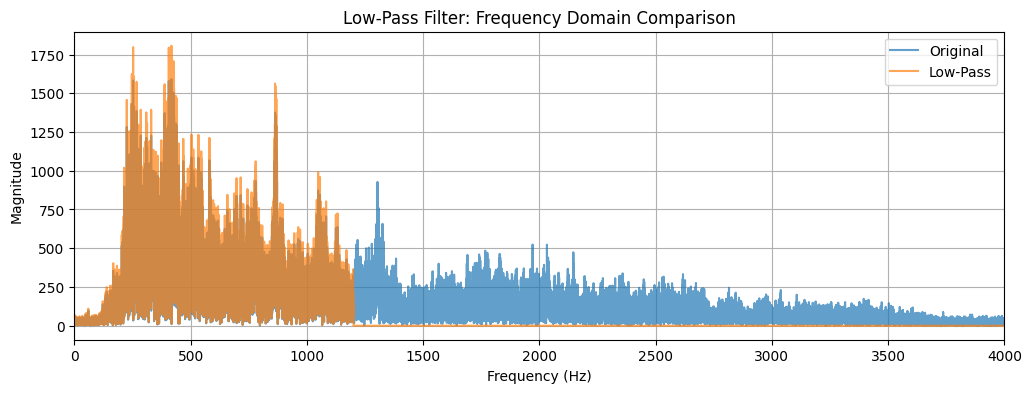

In [ ]:
# Frequency Comparison
lowpass_fft = np.abs(np.fft.fft(lowpass_signal))[:len(signal)//2]

plt.figure(figsize=(12, 4))
plt.plot(positive_freqs, positive_fft, label="Original", alpha=0.7)
plt.plot(positive_freqs, lowpass_fft, label="Low-Pass", alpha=0.7)

plt.title("Low-Pass Filter: Frequency Domain Comparison")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, 4000)
plt.legend()
plt.grid(True)
plt.show()

### Bandpass Filter Effect

A bandpass filter allows frequencies within a specific range (between a lower cutoff frequency $f_{c1}$ and an upper cutoff frequency $f_{c2}$) to pass through, while attenuating frequencies outside this range. This is particularly useful for isolating specific frequency bands, such as those present in human speech.

In the frequency domain, if $X(k)$ is the DFT of $x[n]$, the filtered FFT $Y(k)$ is defined as:

$$Y(k) = \begin{cases} X(k) & \text{if } f_{c1} \le |f_k| \le f_{c2} \\ 0 & \text{otherwise} \end{cases}$$

Where $f_k$ are the frequencies corresponding to the DFT bins. The inverse DFT of $Y(k)$ then yields the bandpass filtered signal $y[n]$ in the time domain.

In [ ]:
# Bandpass Filter Effect
# Keeps frequencies within a specific range (telephone-style voice)

low_cutoff = 1000   # Hz (lower bound of speech)
high_cutoff = 2000 # Hz (upper bound of speech)

print(f"Bandpass Filter Range: {low_cutoff}-{high_cutoff} Hz")
print(f"Original signal length: {len(signal)} samples")

# FFT of signal
fft_vals = np.fft.fft(signal)

# Frequency axis
freqs = np.fft.fftfreq(len(signal), 1/sr)

# Copy FFT
bandpass_fft = np.copy(fft_vals)

# Apply bandpass filter
for i in range(len(freqs)):
    if not (low_cutoff <= abs(freqs[i]) <= high_cutoff):
        bandpass_fft[i] = 0

# Inverse FFT
bandpass_signal = np.real(np.fft.ifft(bandpass_fft))

# Normalize
bandpass_signal = bandpass_signal / np.max(np.abs(bandpass_signal))

print(f"Bandpass filtered signal length: {len(bandpass_signal)} samples")

# Play result
display(Audio(bandpass_signal, rate=sr))

Bandpass Filter Range: 1000-2000 Hz
Original signal length: 340992 samples
Bandpass filtered signal length: 340992 samples


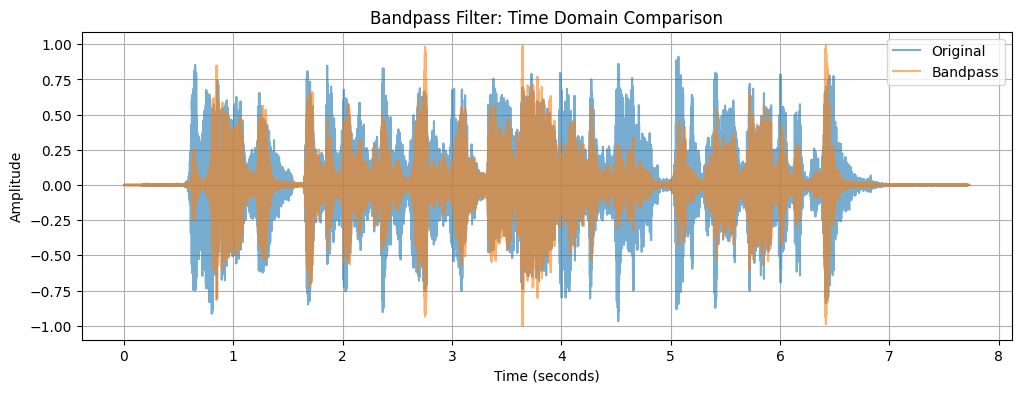

In [ ]:
# Time Comparison

plt.figure(figsize=(12, 4))
plt.plot(time, signal, label="Original", alpha=0.6)
plt.plot(time, bandpass_signal, label="Bandpass", alpha=0.6)

plt.title("Bandpass Filter: Time Domain Comparison")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

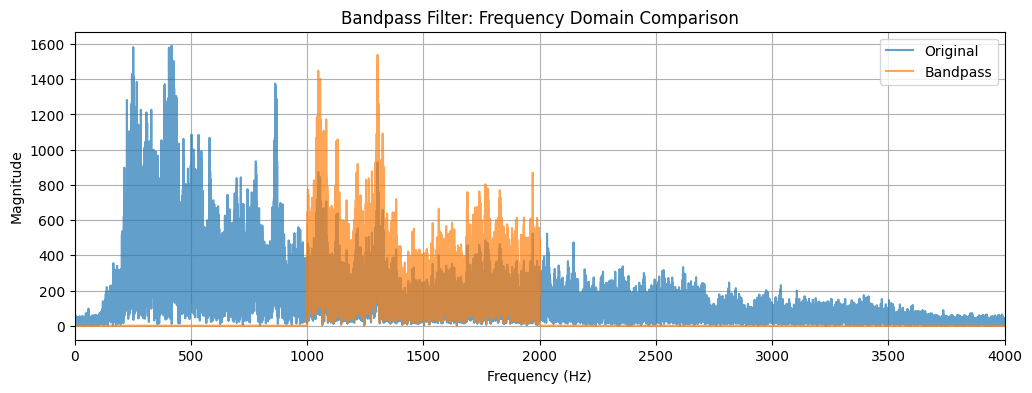

In [ ]:
# Frequency Comparison

bandpass_fft_mag = np.abs(np.fft.fft(bandpass_signal))[:len(signal)//2]

plt.figure(figsize=(12, 4))
plt.plot(positive_freqs, positive_fft, label="Original", alpha=0.7)
plt.plot(positive_freqs, bandpass_fft_mag, label="Bandpass", alpha=0.7)

plt.title("Bandpass Filter: Frequency Domain Comparison")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, 4000)
plt.legend()
plt.grid(True)
plt.show()

### High-Pass Filter Effect

A high-pass filter allows frequencies above a certain cutoff frequency to pass through and attenuates or removes frequencies below it. This is the inverse operation of a low-pass filter, useful for removing low-frequency noise or emphasizing higher-frequency components.

In the frequency domain, if $X(k)$ is the DFT of a signal $x[n]$, and $f_c$ is the cutoff frequency, the filtered FFT $Y(k)$ is given by:

$$Y(k) = \begin{cases} X(k) & \text{if } |f_k| \ge f_c \\ 0 & \text{if } |f_k| < f_c \end{cases}$$

Where $f_k$ are the frequencies corresponding to the DFT bins. The inverse DFT of $Y(k)$ is then computed to obtain the high-pass filtered signal $y[n]$ in the time domain.

In [ ]:
# High-Pass Filter Effect
# Removes low frequencies, keeps high frequencies

cutoff = 1800  # Hz (frequencies below this are removed)

print(f"High-Pass Filter Cutoff Frequency: {cutoff} Hz")
print(f"Original signal length: {len(signal)} samples")

# FFT of signal
fft_vals = np.fft.fft(signal)

# Frequency axis
freqs = np.fft.fftfreq(len(signal), 1/sr)

# Copy FFT
highpass_fft = np.copy(fft_vals)

# Apply high-pass filter
for i in range(len(freqs)):
    if abs(freqs[i]) < cutoff:
        highpass_fft[i] = 0

# Inverse FFT to get filtered signal
highpass_signal = np.fft.ifft(highpass_fft).real

# Normalize
highpass_signal = highpass_signal / np.max(np.abs(highpass_signal))

print(f"High-pass filtered signal length: {len(highpass_signal)} samples")

# Play result
display(Audio(highpass_signal, rate=sr))

High-Pass Filter Cutoff Frequency: 1800 Hz
Original signal length: 340992 samples
High-pass filtered signal length: 340992 samples


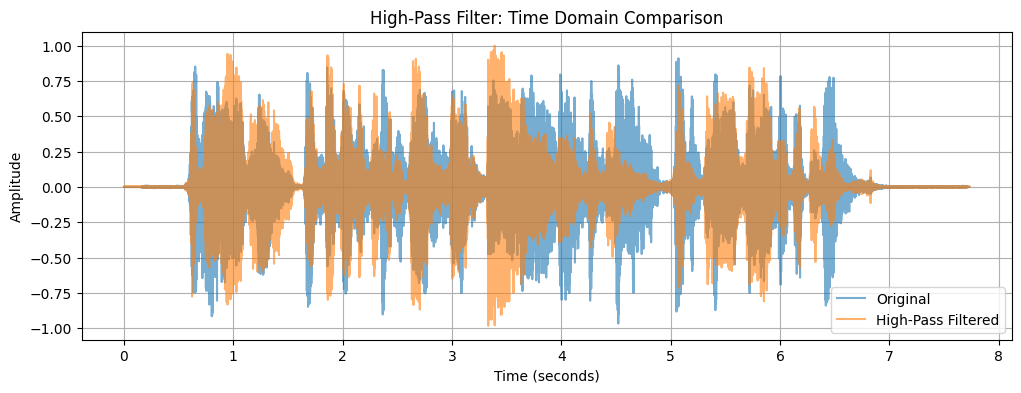

In [ ]:
# Time Comparison
plt.figure(figsize=(12, 4))
plt.plot(time, signal, label="Original", alpha=0.6)
plt.plot(time, highpass_signal, label="High-Pass Filtered", alpha=0.6)

plt.title("High-Pass Filter: Time Domain Comparison")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

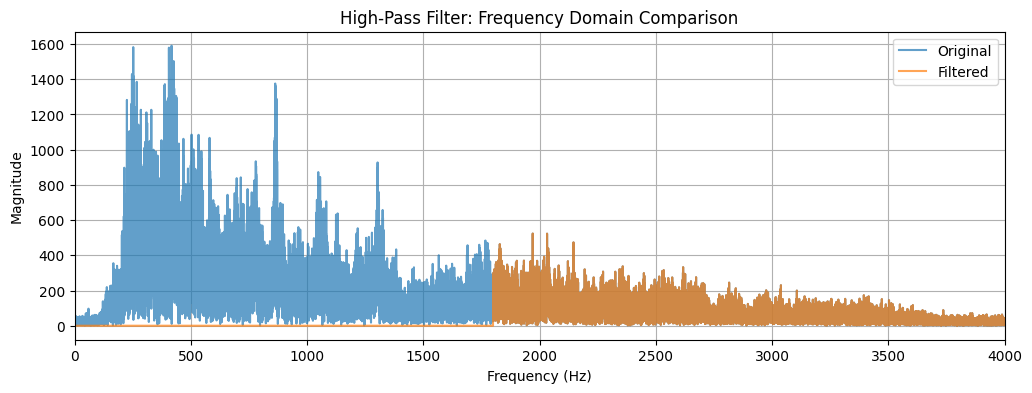

In [ ]:
# Frequency Comparison
highpass_fft_mag = np.abs(highpass_fft)[:len(signal)//2]

plt.figure(figsize=(12, 4))
plt.plot(positive_freqs, positive_fft, label="Original", alpha=0.7)
plt.plot(positive_freqs, highpass_fft_mag, label="Filtered", alpha=0.7)

plt.title("High-Pass Filter: Frequency Domain Comparison")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, 4000)
plt.legend()
plt.grid(True)
plt.show()

### Echo Effect

An echo effect is created by adding a delayed and attenuated (scaled) version of the original signal to itself. The mathematical representation of a simple echo is:

$$y[n] = x[n] + \alpha \cdot x[n - D]$$

Where:
- $y[n]$ is the output signal with echo.
- $x[n]$ is the original input signal.
- $\alpha$ (alpha) is the attenuation factor (strength) of the echo, typically between 0 and 1.
- $D$ is the delay in samples.

This equation means that for each sample $n$ in the output signal, we take the original sample $x[n]$ and add to it a previous sample $x[n-D]$ scaled by $\alpha$.

In [ ]:
# Echo Effect
# Adds a delayed and scaled version of the signal

delay = 0.3  # seconds
alpha = 0.6  # echo strength

# Convert delay to samples
delay_samples = int(delay * sr)

print(f"Echo Delay: {delay}s ({delay_samples} samples), Strength (alpha): {alpha}")
print(f"Original signal length: {len(signal)} samples")

# Copy original signal
echo_signal = np.copy(signal)

# Apply echo
for i in range(delay_samples, len(signal)):
    echo_signal[i] += alpha * signal[i - delay_samples]

# Normalize to avoid clipping
echo_signal = echo_signal / np.max(np.abs(echo_signal))

print(f"Echo signal length: {len(echo_signal)} samples")

# Play result
display(Audio(echo_signal, rate=sr))

Echo Delay: 0.3s (13230 samples), Strength (alpha): 0.6
Original signal length: 340992 samples
Echo signal length: 340992 samples


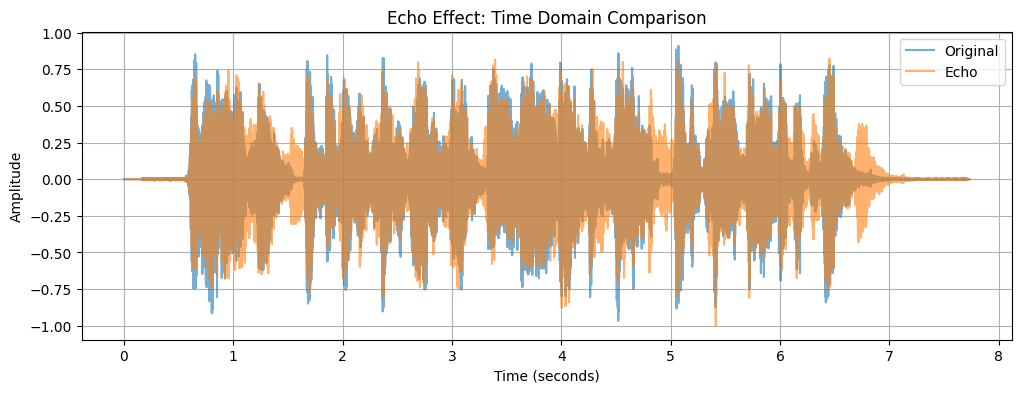

In [ ]:
# Echo Time Comparison

plt.figure(figsize=(12, 4))

plt.plot(time, signal, label="Original", alpha=0.6)
plt.plot(time, echo_signal, label="Echo", alpha=0.6)

plt.title("Echo Effect: Time Domain Comparison")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

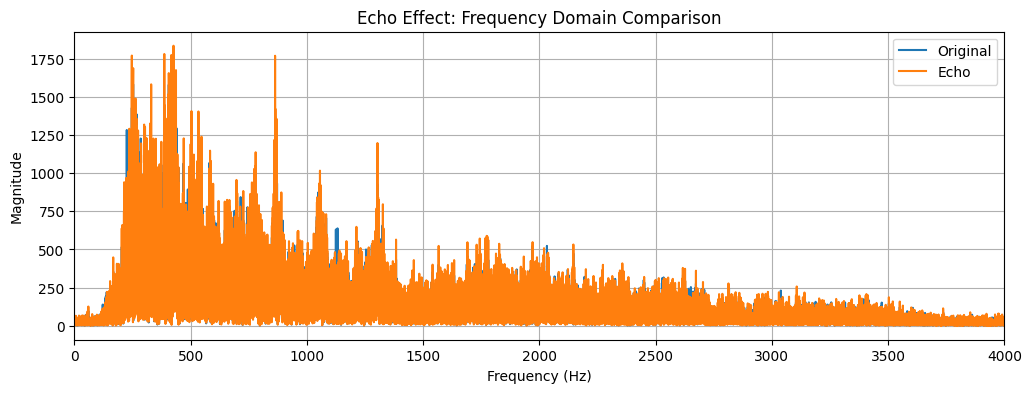

In [ ]:
# FFT of echo signal
echo_fft = np.abs(np.fft.fft(echo_signal))[:len(signal)//2]

plt.figure(figsize=(12, 4))
plt.plot(positive_freqs, positive_fft, label="Original")
plt.plot(positive_freqs, echo_fft, label="Echo")

plt.title("Echo Effect: Frequency Domain Comparison")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, 4000)
plt.legend()
plt.grid(True)
plt.show()

### Reverb Effect

Reverberation (reverb) is a more complex effect that simulates the reflections of sound in an enclosed space. It's often implemented using a series of closely spaced echoes, creating a dense decay. Mathematically, reverb is typically modeled as a convolution of the original signal with an impulse response, $h[n]$, that represents the acoustic properties of the environment:

$$y[n] = x[n] * h[n]$$

Where:
- $y[n]$ is the reverberated output signal.
- $x[n]$ is the original input signal.
- $h[n]$ is the impulse response, which is a sum of delayed and attenuated impulses representing the reflections.
- $*$ denotes the convolution operation.

In our implementation, the impulse response $h[n]$ is constructed by placing weighted impulses at specific delay points, and then convolving this $h[n]$ with the original signal.

In [ ]:
# Reverb Effect
# Uses an impulse response to simulate reflections

# Delays (in samples)
delay1 = int(0.03 * sr)
delay2 = int(0.06 * sr)
delay3 = int(0.09 * sr)
delay4 = int(0.12 * sr)
delay5 = int(0.15 * sr)

# Strengths
alpha1 = 0.7
alpha2 = 0.5
alpha3 = 0.4
alpha4 = 0.3
alpha5 = 0.2

print(f"Reverb Delays (samples): {delay1}-{delay5}, Strengths (alpha): {alpha1}-{alpha5}")
print(f"Original signal length: {len(signal)} samples")

# Length of impulse response
max_delay = delay5
h = np.zeros(max_delay + 1)

# Direct signal
h[0] = 1

# Add delayed impulses
h[delay1] = alpha1
h[delay2] = alpha2
h[delay3] = alpha3
h[delay4] = alpha4
h[delay5] = alpha5

# Apply convolution
reverb_signal = np.convolve(signal, h)

# Trim to original length
reverb_signal = reverb_signal[:len(signal)]

print(f"Reverb signal length (trimmed): {len(reverb_signal)} samples")

# Normalize
reverb_signal = reverb_signal / np.max(np.abs(reverb_signal))

# Play result
display(Audio(reverb_signal, rate=sr))

Reverb Delays (samples): 1323-6615, Strengths (alpha): 0.7-0.2
Original signal length: 340992 samples
Reverb signal length (trimmed): 340992 samples


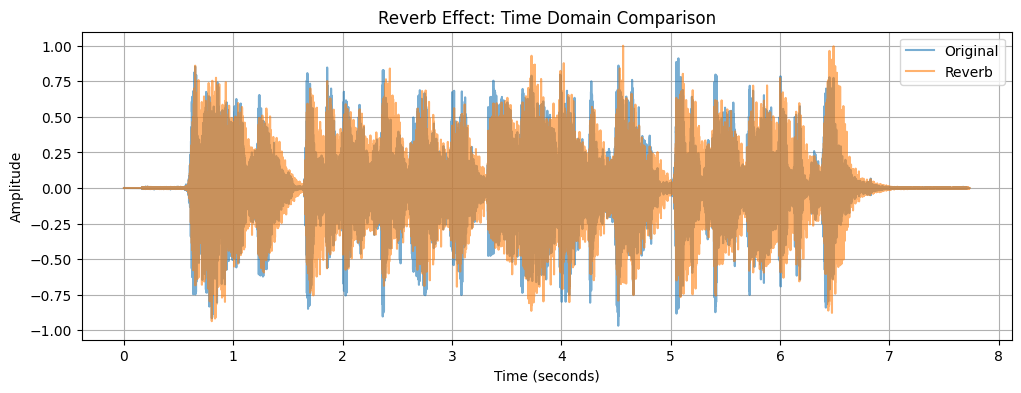

In [ ]:
# Reverb Time Comparison

plt.figure(figsize=(12, 4))

plt.plot(time, signal, label="Original", alpha=0.6)
plt.plot(time, reverb_signal, label="Reverb", alpha=0.6)

plt.title("Reverb Effect: Time Domain Comparison")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

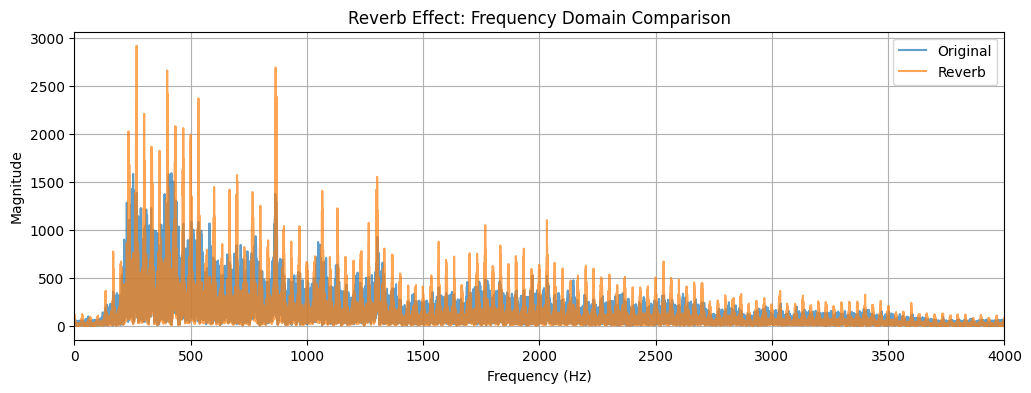

In [ ]:
# Reverb Frequency Comparison

# Compute FFT of reverb signal
reverb_fft = np.fft.fft(reverb_signal)
reverb_fft_magnitude = np.abs(reverb_fft)

# Keep only positive frequencies
reverb_fft_positive = reverb_fft_magnitude[:len(reverb_fft_magnitude)//2]

# Plot comparison
plt.figure(figsize=(12, 4))

plt.plot(positive_freqs, positive_fft, label="Original", alpha=0.7)
plt.plot(positive_freqs, reverb_fft_positive, label="Reverb", alpha=0.7)

plt.title("Reverb Effect: Frequency Domain Comparison")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, 4000)  # focus on voice range
plt.legend()
plt.grid(True)
plt.show()

### High Pitch Effect

Pitch shifting can be achieved through resampling in the time domain. To raise the pitch, the signal is effectively 'sped up' by skipping samples, which compresses it in time.

If $x[n]$ is the original signal with sampling rate $sr$, to achieve a higher pitch with a `pitch_factor` (where `pitch_factor > 1`), we select samples from the original signal at indices $m = \text{floor}(n \cdot \text{pitch_factor})$. This produces a new signal $y[n] = x[\text{floor}(n \cdot \text{pitch_factor})]$.

This operation reduces the number of samples while keeping the playback rate the same. As a result, the signal is compressed in time, leading to a higher perceived pitch and a shorter duration (i.e., faster tempo).

In [ ]:
# High Pitch Effect
# Speeds up the signal to increase pitch

pitch_factor = 2  # >1 raises pitch

print(f"High Pitch Factor: {pitch_factor}")
print(f"Original signal length: {len(signal)} samples")

# Generate new indices
indices = np.arange(0, len(signal), pitch_factor)
indices = indices[indices < len(signal)].astype(int)

# Apply resampling
high_pitch_signal = signal[indices]

print(f"High pitch signal length (adjusted): {len(high_pitch_signal)} samples")

# Pad to original length for comparison
# (This logic correctly handles cases where high_pitch_signal is shorter)
if len(high_pitch_signal) < len(signal):
    high_pitch_signal = np.pad(high_pitch_signal, (0, len(signal) - len(high_pitch_signal)))
elif len(high_pitch_signal) > len(signal):
    high_pitch_signal = high_pitch_signal[:len(signal)] # Added this for consistency, though not strictly needed for pitch_factor > 1

# Normalize
high_pitch_signal = high_pitch_signal / np.max(np.abs(high_pitch_signal))

# Play result
display(Audio(high_pitch_signal, rate=sr))

High Pitch Factor: 2
Original signal length: 340992 samples
High pitch signal length (adjusted): 170496 samples


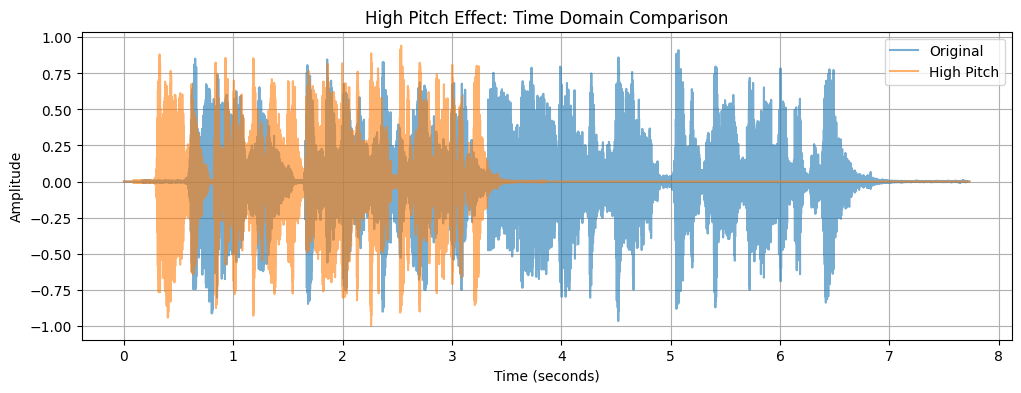

In [ ]:
# High Pitch Time Comparison

plt.figure(figsize=(12, 4))

plt.plot(time, signal, label="Original", alpha=0.6)
plt.plot(time, high_pitch_signal, label="High Pitch", alpha=0.6)

plt.title("High Pitch Effect: Time Domain Comparison")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

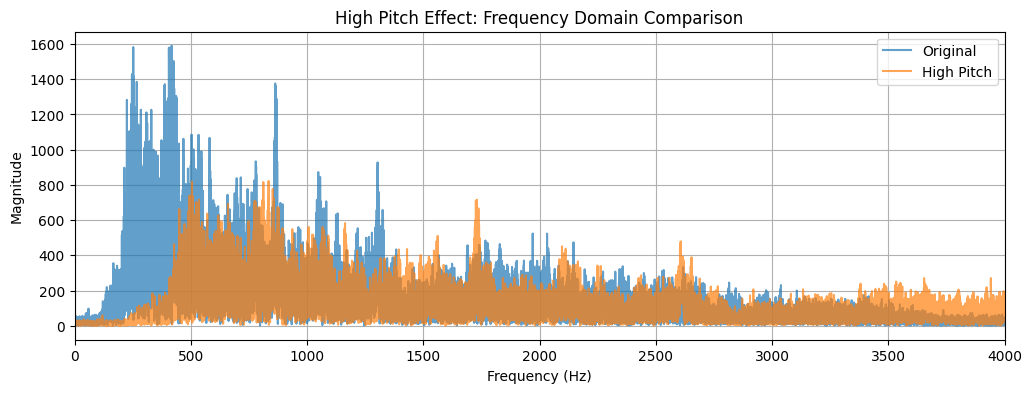

In [ ]:
# High Pitch Frequency Comparison

# Compute FFT of high pitch signal
hp_fft = np.fft.fft(high_pitch_signal)
hp_fft_magnitude = np.abs(hp_fft)

# Keep only positive frequencies
hp_fft_positive = hp_fft_magnitude[:len(hp_fft_magnitude)//2]

# Plot comparison
plt.figure(figsize=(12, 4))

plt.plot(positive_freqs, positive_fft, label="Original", alpha=0.7)
plt.plot(positive_freqs, hp_fft_positive, label="High Pitch", alpha=0.7)

plt.title("High Pitch Effect: Frequency Domain Comparison")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, 4000)
plt.legend()
plt.grid(True)
plt.show()

### Low Pitch Effect

The low pitch effect is achieved by stretching the signal in the time domain using interpolation. Instead of skipping samples, new sample points are inserted between existing ones to increase the signal length.

To do this, a new set of sample positions is created over a longer time axis, and the values at these positions are computed using linear interpolation between neighboring samples.

This increases the number of samples while keeping the playback rate the same. As a result, the signal is stretched in time, leading to a lower perceived pitch and a longer duration.

In [ ]:
# Low Pitch Effect
# Slows down the signal to decrease pitch using interpolation

pitch_factor = 0.5  # <1 lowers pitch

print(f"Low Pitch Factor: {pitch_factor}")
print(f"Original signal length: {len(signal)} samples")

# Original sample positions
original_indices = np.arange(len(signal))

# New sample positions (stretched time axis)
new_length = int(len(signal) / pitch_factor)
new_indices = np.linspace(0, len(signal) - 1, new_length)

# Interpolate signal (linear interpolation)
low_pitch_signal = np.interp(new_indices, original_indices, signal)

print(f"Low pitch signal length (interpolated): {len(low_pitch_signal)} samples")

# Normalize
low_pitch_signal = low_pitch_signal / np.max(np.abs(low_pitch_signal))

# Play result (LONGER audio now)
display(Audio(low_pitch_signal, rate=sr))

Low Pitch Factor: 0.5
Original signal length: 340992 samples
Low pitch signal length (interpolated): 681984 samples


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


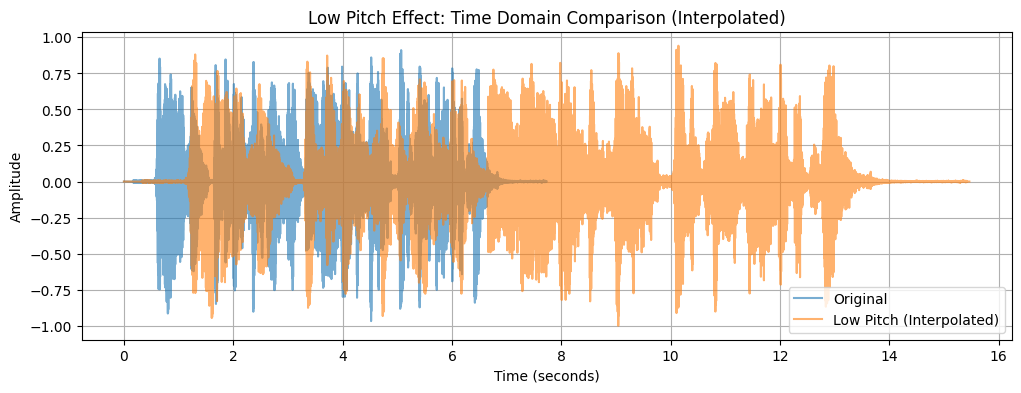

In [ ]:
# Low Pitch Time Comparison

low_time = np.linspace(0, len(low_pitch_signal)/sr, len(low_pitch_signal))

plt.figure(figsize=(12, 4))

plt.plot(time, signal, label="Original", alpha=0.6)
plt.plot(low_time, low_pitch_signal, label="Low Pitch (Interpolated)", alpha=0.6)

plt.title("Low Pitch Effect: Time Domain Comparison (Interpolated)")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

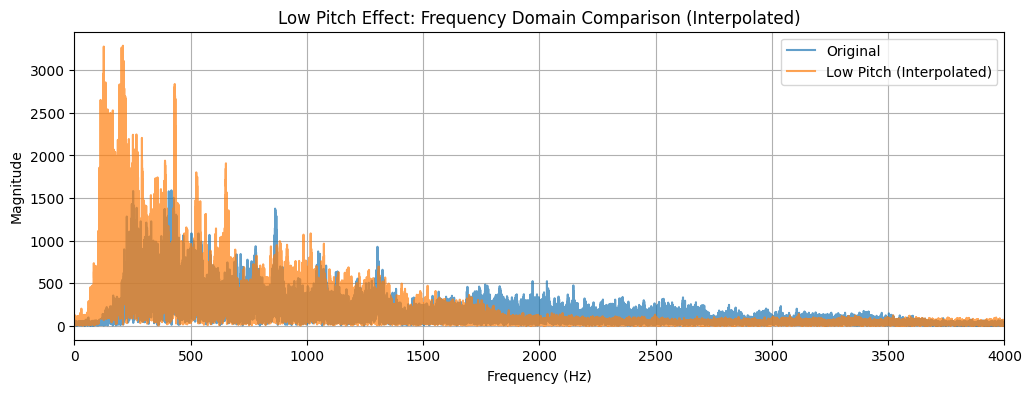

In [ ]:
# FFT of low pitch signal
lp_fft = np.fft.fft(low_pitch_signal)
lp_fft_magnitude = np.abs(lp_fft)

lp_fft_positive = lp_fft_magnitude[:len(lp_fft_magnitude)//2]

# New frequency axis (because length changed)
lp_freqs = np.fft.fftfreq(len(low_pitch_signal), 1/sr)
lp_freqs_positive = lp_freqs[:len(lp_freqs)//2]

plt.figure(figsize=(12, 4))

plt.plot(positive_freqs, positive_fft, label="Original", alpha=0.7)
plt.plot(lp_freqs_positive, lp_fft_positive, label="Low Pitch (Interpolated)", alpha=0.7)

plt.title("Low Pitch Effect: Frequency Domain Comparison (Interpolated)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, 4000)
plt.legend()
plt.grid(True)
plt.show()

## Conclusion
This project demonstrated how a voice signal can be analyzed and modified using fundamental signals and systems concepts. The signal was first visualized in the time domain and then transformed into the frequency domain using the Fourier Transform to examine its spectral content.

Multiple audio effects were implemented, including low-pass filtering, bandpass filtering, high-pass filtering, echo, reverb, high pitch, and low pitch. The filtering effects demonstrated how modifying a signal in the frequency domain can selectively remove or preserve certain frequency components. Echo and reverb illustrated time shifting, scaling, superposition, and convolution. The pitch shifting effects showcased how resampling in the time domain can alter the perceived fundamental frequency of the audio, effectively raising or lowering the pitch.

By comparing signals before and after each transformation in both the time and frequency domains, this project highlights how different signal processing techniques influence the structure and perception of audio signals, providing a comprehensive application of key concepts in signals and systems.